# L10 · NB 02 — Attention, intuitively

> ⏱️ **~25 min** core (Sections 1–8) · +25 min for the 🟡 Extension · one small model (`all-MiniLM-L6-v2`, ~90 MB — the same one from L09) — runs on any laptop

> *We've used transformers as black boxes for two lessons. Time to open one up. The single mechanism that makes everything work is **attention**. The core of this notebook needs **no maths** — just a few everyday sentences, starting with one about a trophy and a suitcase.*

By the end of this notebook you will:

1. Be able to explain attention in plain English — "each word looks around the sentence and decides who to listen to"
2. Understand what queries, keys, and values are *for* — a question, a name tag, and an info card
3. Be able to read an attention heatmap, and see why models use several attention "heads" at once
4. Be ready to USE pretrained transformers in NB 03 without it feeling like magic

> 🧮 **Curious about the maths?** The matrix version of attention lives in **Extension E1** at the end. It's optional — nothing later in the course depends on it.

---

### Where you are in L10

Marcus asked for a shopping assistant. Sarah can't build it in one leap — she works through four notebooks, each answering the next question in the chain:

| Step | Notebook | Sarah's question |
|---|---|---|
| 1 | `01_morning_briefing` | What can pretrained transformers already do, out of the box? |
| 2 | `02_attention_intuition` 👈 **you are here** | *Why* do they work? What is this "attention" everyone talks about? |
| 3 | `03_using_an_llm` | How do I drive a generative LLM myself — tokens, sampling, chat? |
| 4 | `04_rag_pipeline` | How do I ground it in NorthStar's catalogue? → the shopping assistant |

Right now you're on **step 2 of 4**. Each notebook stands on the one before it — run them in order.

## 1 · Setup


> **Why this cell first.**
> No big models here — just one small model in Section 3, loaded there. The setup just imports our plotting tools and **fixes the random seeds** (`torch.manual_seed(0)`, `np.random.seed(0)`), so the transformer block in Section 6 (and the optional maths in the Extension) gives the same numbers every time you run it.

In [2]:
# numpy for simple arithmetic, torch for the transformer block later,
# matplotlib + seaborn for bar charts and heatmaps.
import logging
# Silence harmless torch notice "Redirects are currently not supported in MacOs" (must run before torch is imported)
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(0)      # same random numbers every run
np.random.seed(0)

# Our running example — the first 6 words of the classic trophy/suitcase sentence.
# We'll use these 6 for the heatmaps (a small grid is easier to read).
TOKENS = ['the', 'trophy', "didn't", 'fit', 'because', 'it']
print(f"Sequence: {TOKENS}")

Sequence: ['the', 'trophy', "didn't", 'fit', 'because', 'it']


## 2 · What is attention? (the ELI5 version)

Read these two sentences:

> The trophy didn't fit in the suitcase because **it** was too **big**.
>
> The trophy didn't fit in the suitcase because **it** was too **small**.

You know instantly: in the first, *it* = the **trophy**. In the second, *it* = the **suitcase**. How? Without thinking about it, you glanced back at the other words and asked *"which one makes sense here?"* — something too big can't go *in*; something too small can't *hold*.

**That glance back is attention.** A transformer does exactly this, for every word, at the same time.

### The classroom analogy

Imagine every word in the sentence is a student in a classroom.

- 🙋 **"it" raises its hand and asks a question:** *"I'm something that's too big — who am I?"* → that question is the **query (Q)**
- 🏷️ **Every other word wears a name tag** describing itself: *trophy — "I'm an object"*, *suitcase — "I'm a container"*, *the — "I'm just a filler word"* → those name tags are the **keys (K)**
- 👀 **"it" looks around the room** and checks how well each name tag matches its question. Good match → listen closely. Poor match → mostly ignore. → those are the **attention weights**
- 📇 **Every word also holds an info card** with what it actually means. "it" copies notes from the cards — lots from the best match, a little from the rest. → those cards are the **values (V)**

After this, "it" is no longer a vague word. It now *carries the meaning* of "trophy" (or "suitcase").

| Piece | In the classroom | In plain English |
|---|---|---|
| **Query** | the question you ask | "what am I looking for?" |
| **Key** | the name tag you wear | "here's what I am" |
| **Value** | the info card you hold | "here's what I'll share" |
| **Attention weights** | how closely you listen to each classmate | percentages that add up to 100% |

> 💡 **Nobody writes these questions and name tags by hand.** The model *learns* them by reading billions of sentences. Our job today is just to understand what it's doing.

## 3 · Watch a real model decide

Enough storytelling — let's look inside an actual trained transformer and see who **it** listens to.

We'll use **`all-MiniLM-L6-v2`** — the same small model you used for embeddings in L09. It has 6 layers × 12 heads, and it learned its attention patterns by reading over a billion sentence pairs. Nobody typed any of the numbers you're about to see.

What the next cell does, in plain English:

1. Feed a sentence into the model and ask it to **report its attention** as well as its answer
2. Look at the **last layer** (where the model has had the most time to "think"), and **average its 12 heads** — so we're not cherry-picking one lucky head
3. Pull out the row for one word — e.g. **"it"** — and draw it as a bar chart: *how much is "it" listening to each other word?*

> **Two bits of housekeeping.** The model adds two invisible marker tokens, `[CLS]` at the start and `[SEP]` at the end, and real models park a lot of spare attention on them (a "nothing important here" default). We also hide the word listening to *itself*. We drop those three and re-scale the rest to 100%, so the bars show only the real words.

In [3]:
# Load a small pretrained transformer (~90 MB, downloads once, then cached).
# attn_implementation="eager" makes the model hand back its attention weights.
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME, attn_implementation='eager').eval()


def get_attention(sentence, word, layer=-1):
    """Return (tokens, % of attention) that `word` pays to every other token, in one layer, averaged over heads."""
    enc = tokenizer(sentence, return_tensors='pt')
    tokens = tokenizer.convert_ids_to_tokens(enc.input_ids[0])
    assert word in tokens, f'"{word}" is not a single token here — the model sees: {tokens}'
    with torch.no_grad():
        attentions = model(**enc, output_attentions=True).attentions   # one (1, heads, n, n) tensor per layer
    i = tokens.index(word)
    row = attentions[layer][0].mean(dim=0)[i].clone()   # average the heads, keep the row for `word`
    row[0] = row[-1] = row[i] = 0                         # hide [CLS], [SEP] and the word itself
    pct = (row / row.sum() * 100).numpy()                 # re-scale the rest to 100%
    return tokens[1:-1], pct[1:-1]


def show_attention(sentence, word='it'):
    """Draw who `word` listens to in the model's last layer, as a bar chart."""
    tokens, pct = get_attention(sentence, word)
    colours = ['tab:green' if p == pct.max() else 'lightgray' for p in pct]   # highlight the winner
    fig, ax = plt.subplots(figsize=(10, 3))
    bars = ax.bar(range(len(tokens)), pct, color=colours)
    ax.set_xticks(range(len(tokens)), tokens, rotation=30)
    ax.bar_label(bars, fmt='%.0f%%', fontsize=9)
    ax.set_ylabel('% of attention')
    ax.set_ylim(0, 60)
    ax.set_title(f'Who does "{word}" listen to?  (real model: {MODEL_NAME.split("/")[-1]}, last layer)')
    plt.tight_layout()
    plt.show()


print(f'Loaded {MODEL_NAME}: {model.config.num_hidden_layers} layers × {model.config.num_attention_heads} heads')

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded sentence-transformers/all-MiniLM-L6-v2: 6 layers × 12 heads


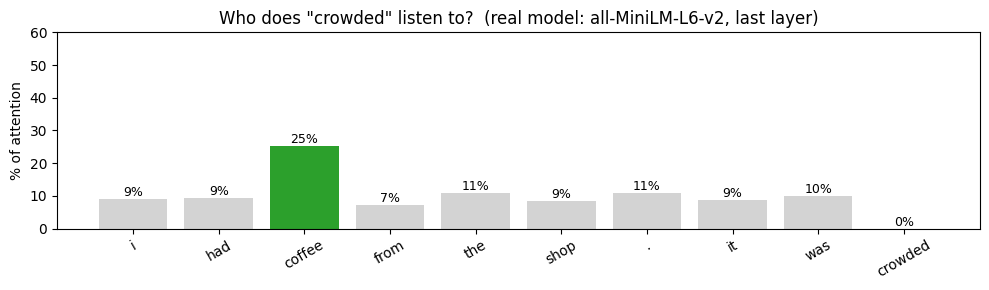

In [32]:
# Sarah is reading a customer review. What is "it"?
# The model tokenizes "It" as lowercase "it"
show_attention("I had coffee from the shop. it was crowded", word='crowded')

### A challenging example for attention

Let's test the famous **trophy vs suitcase** riddle that we discussed earlier. A small model like `all-MiniLM-L6-v2` lacks the real-world knowledge to understand that "too big" refers to the trophy, or "too small" refers to the suitcase. Instead, it often defaults to structural shortcuts (like attending heavily to the first noun or the nearest entity).

--- Scenario A: too big (it should refer to trophy) ---


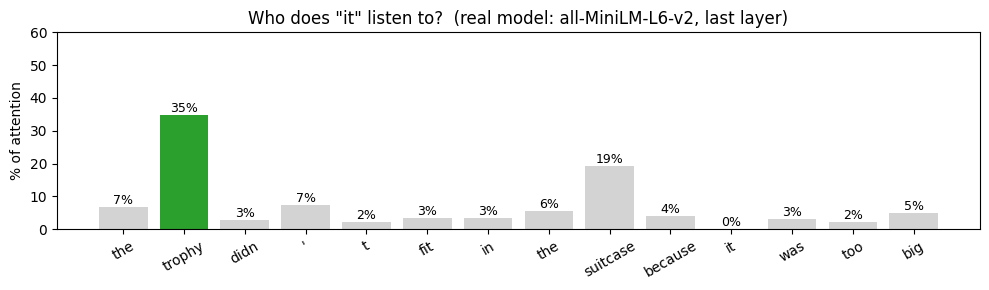

--- Scenario B: too small (it should refer to suitcase) ---


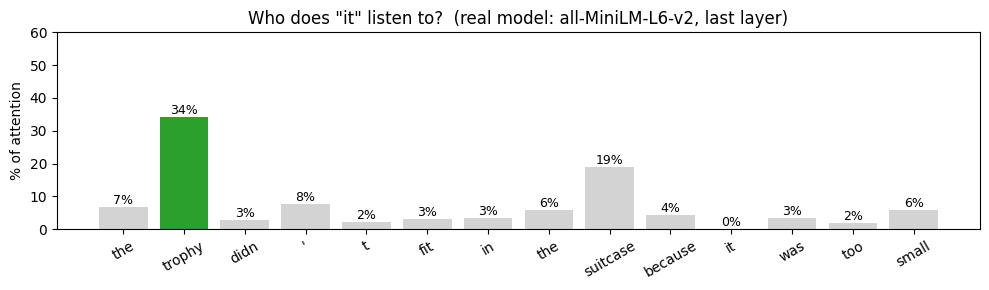

In [33]:
# Test how the model struggles to resolve "it" when we change the adjective
print("--- Scenario A: too big (it should refer to trophy) ---")
show_attention("the trophy didn't fit in the suitcase because it was too big", word='it')

print("--- Scenario B: too small (it should refer to suitcase) ---")
show_attention("the trophy didn't fit in the suitcase because it was too small", word='it')

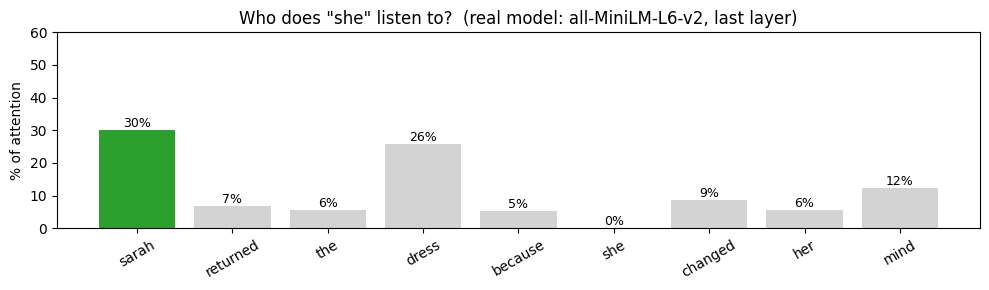

In [5]:
# Same opening words — but now the pronoun is "she". Who should she listen to?
show_attention("sarah returned the dress because she changed her mind", word='she')

**Same opening words, different pronoun — and the real model's attention flips.** "it" listens most to **dress** (a thing that can be too small); "she" listens most to **sarah** (a person who can change her mind). Nobody told the model that "it" means objects and "she" means people — it picked that up from reading.

Three things to notice about **real** attention, compared with the tidy story in Section 2:

- **The winner wins, but not by a landslide.** You'll see ~30%, not 90%. Each word keeps listening a bit to everything — the runner-up (*sarah* for "it", *dress* for "she") still gets a decent share.
- **Filler words get very little.** *the*, *because*, *was* sit near the bottom. Part of what a model learns is **what to ignore**.
- **This is one layer, averaged over 12 heads.** The model's full understanding is spread across all 6 layers and 72 heads — the bar chart is a peek, not the whole picture.

### ✏️ Your turn

1. Run the cell below — does "it" listen to the **cat** or the **road**?
2. Change *tired* to *wide* and run again. A road can be wide; a cat can't. Does the model notice?
3. Try a sentence of your own — e.g. `"the customer returned the jacket because it was torn"`. Keep it lowercase, and pass the pronoun you want to inspect as `word=`.

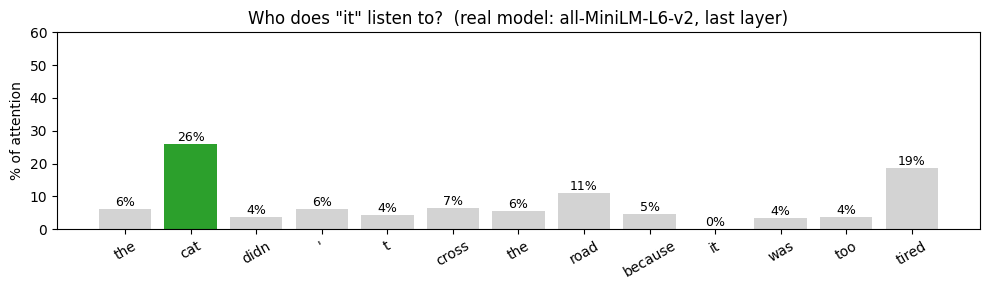

In [6]:
show_attention("the cat didn't cross the road because it was too tired", word='it')   # <-- edit the sentence

**What happened with "wide"?** When we tested it, the model *still* listened mostly to **cat** — it didn't flip to *road*. That's a real blind spot: a small model leans on simple habits (e.g. "it" usually means the first noun) rather than common sense about cats and roads.

This is exactly why the **trophy / suitcase** pair from Section 2 is famous: it's a classic test of AI reasoning (the *Winograd* challenge), and small models like this one fail it. Bigger models get it right much more often — which is a big part of why the industry keeps scaling up (Section 7).

### Bonus: watch the answer form, layer by layer

Each layer re-reads the sentence using what the previous layer worked out. Below, each **row** is one of the 6 layers, showing who "it" listens to at that depth.

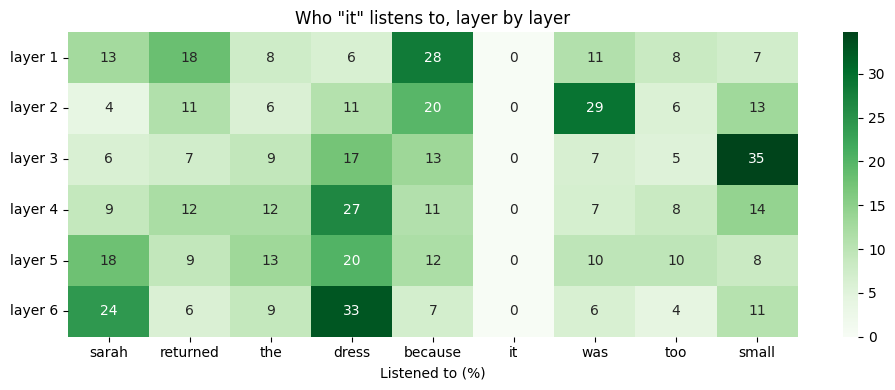

In [7]:
# One row per layer: who does "it" listen to at each depth of the model?
sentence = "sarah returned the dress because it was too small"
rows = []
for layer in range(model.config.num_hidden_layers):
    tokens, pct = get_attention(sentence, 'it', layer=layer)
    rows.append(pct)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(np.array(rows), annot=True, fmt='.0f', cmap='Greens',
            xticklabels=tokens, yticklabels=[f'layer {l + 1}' for l in range(len(rows))], ax=ax)
ax.set_xlabel('Listened to (%)')
ax.tick_params(axis='y', rotation=0)
ax.set_title('Who "it" listens to, layer by layer')
plt.tight_layout()
plt.show()

Read it top to bottom. In the **early layers**, "it" mostly glances at its **neighbours** (*because*, *was*, *small*) — working out the local grammar. By the **later layers**, it has settled on **dress**. The model doesn't jump to the answer in one step; it builds it up, layer by layer — which is why transformers stack many blocks (Section 6).

## 4 · The whole room at once — reading an attention heatmap

So far we only looked at what one word (**"it"** or **"she"**) pays attention to. But in a transformer, **every word asks its own question at the same time**: *"fit"* asks "what is failing to fit?", *"didn't"* asks "which action am I negating?", and so on.

If we stack every word's bar chart on top of each other, we get a grid called an **attention heatmap**:

- **Each row** = one word asking its question (a bar chart like the ones in Section 3, turned sideways)
- **Each column** = a word being listened to
- **Darker cell** = more attention. Each row adds up to 1 (= 100%)

Below is an **idealised** heatmap for our 6-word sentence — numbers typed in by hand so the pattern is easy to read. As you saw in Section 3, real ones are messier: same idea, smaller margins.

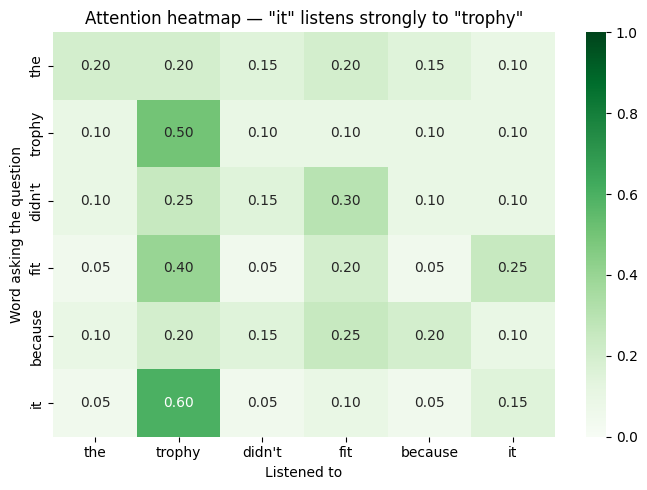

In [8]:
# A hand-typed attention grid — what a trained attention head might learn for this sentence.
# Each row is one word's "bar chart" as fractions (0.60 = 60%), and each row sums to 1.
hand_attn = torch.tensor([
    # the    trophy didn't  fit    because it     <-- listened TO
    [0.20,   0.20,  0.15,   0.20,  0.15,   0.10],   # the
    [0.10,   0.50,  0.10,   0.10,  0.10,   0.10],   # trophy listens mostly to itself
    [0.10,   0.25,  0.15,   0.30,  0.10,   0.10],   # didn't listens to the verb it negates
    [0.05,   0.40,  0.05,   0.20,  0.05,   0.25],   # fit listens to what is (not) fitting
    [0.10,   0.20,  0.15,   0.25,  0.20,   0.10],   # because listens broadly
    [0.05,   0.60,  0.05,   0.10,  0.05,   0.15],   # it listens strongly to trophy!
])

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(hand_attn.numpy(), annot=True, fmt='.2f', cmap='Greens',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=ax)
ax.set_xlabel('Listened to')
ax.set_ylabel('Word asking the question')
ax.set_title('Attention heatmap — "it" listens strongly to "trophy"')
plt.tight_layout()
plt.show()

Look at the bottom row. The word **"it"** puts 0.60 (60%) of its attention on **"trophy"** — the same kind of picture as the bar charts in Section 3, just drawn as a row of coloured squares. That's how the model works out that *it* = *trophy*: when it builds its new understanding of "it", most of the notes it copies come from "trophy".

When you see attention heatmaps in articles or research papers, this is all they are: **who is listening to whom**.

## 5 · Multi-head attention — several questions at once

One question isn't enough to understand a sentence. "it" might want to know **who am I?** *and* **what action am I part of?** — two different questions with two different answers.

So transformers run several attentions side by side, called **heads**. Think of a team of detectives reading the same sentence, each hunting for a different kind of clue: one tracks *who's who*, another tracks *who did what*, another tracks *what describes what*. Each head produces its own heatmap.

Below are two **illustrative** heads with hand-typed numbers, so the contrast is easy to see. (The real bar charts in Section 3 were the *average* of 12 such heads.)

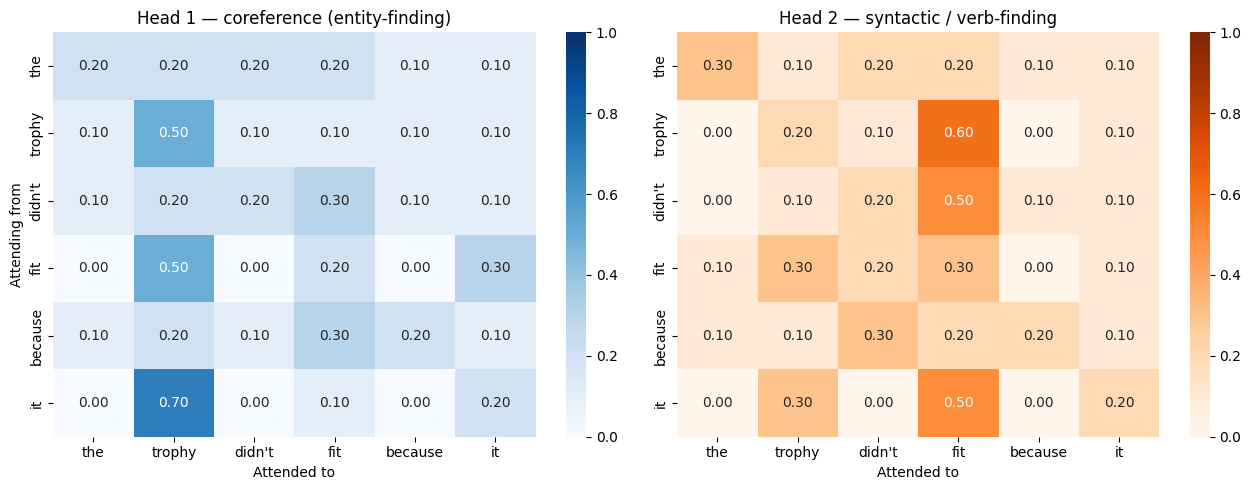

In [9]:
# Demonstrate two attention heads with different focus patterns.
# Each head is its own (6x6) attention matrix — same sentence, different relationship learned.
head_1 = torch.tensor([
    # 'it' focuses on entities
    [0.2, 0.2, 0.2, 0.2, 0.1, 0.1],
    [0.1, 0.5, 0.1, 0.1, 0.1, 0.1],
    [0.1, 0.2, 0.2, 0.3, 0.1, 0.1],
    [0.0, 0.5, 0.0, 0.2, 0.0, 0.3],
    [0.1, 0.2, 0.1, 0.3, 0.2, 0.1],
    [0.0, 0.7, 0.0, 0.1, 0.0, 0.2],   # 'it' -> 'trophy' (coreference head)
])
head_2 = torch.tensor([
    # focuses on syntax / verb structure
    [0.3, 0.1, 0.2, 0.2, 0.1, 0.1],
    [0.0, 0.2, 0.1, 0.6, 0.0, 0.1],   # 'trophy' attends to verb 'fit'
    [0.0, 0.1, 0.2, 0.5, 0.1, 0.1],
    [0.1, 0.3, 0.2, 0.3, 0.0, 0.1],
    [0.1, 0.1, 0.3, 0.2, 0.2, 0.1],
    [0.0, 0.3, 0.0, 0.5, 0.0, 0.2],   # 'it' attends to verb (different from head 1)
])

# Plot both heads side by side to see they capture different relationships from the same input.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(head_1.numpy(), annot=True, fmt='.2f', cmap='Blues',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=axes[0])
axes[0].set_title('Head 1 — coreference (entity-finding)')
axes[0].set_xlabel('Attended to'); axes[0].set_ylabel('Attending from')

sns.heatmap(head_2.numpy(), annot=True, fmt='.2f', cmap='Oranges',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('Head 2 — syntactic / verb-finding')
axes[1].set_xlabel('Attended to')

plt.tight_layout()
plt.show()

**Two heads, two completely different patterns.** In Head 1 (the "who's who" detective), "it" listens to "trophy". In Head 2 (the "who did what" detective), "it" listens to "fit". Both clues are useful; combining them is what gives a transformer its rich understanding of each word.

In a real model: typically 12–16 heads per layer (GPT-3 uses 96) × 12–96 layers. Nobody assigns the heads their jobs — each one picks up its speciality during training. Some end up tracking grammar, some meaning, some long-range connections.

## 6 · The transformer block — putting it together

So far we've seen **attention** in a real model and in illustrated heatmaps: a way for each token to look at every other token and pull in a weighted mix of their information. That's the heart of a transformer — but it's not the *whole* thing.

A real transformer wraps attention in a small, repeating package called a **transformer block**. Think of attention as the engine, and the block as the car built around it. Every block does the same steps, in order:

```
                  ┌──────────────────────────────────────────────┐
   input x ──────►│  1. Multi-head Attention   (tokens mix info)  │
                  │  2. Add + LayerNorm   (x + attention) ◄─────── residual
                  │  3. Feed-forward      (think about each token)│
                  │  4. Add + LayerNorm   (x + feed-forward) ◄──── residual
                  └──────────────────────────────────────────────┘
                                    │
                                    ▼  output (same shape as input)
```

Attention you already understand. The new pieces are each simple — here's the intuition for *why* they exist:

**Feed-forward** — a tiny 2-layer neural network applied to each token *on its own* (no mixing between tokens). Attention gathers information from other tokens; the feed-forward layer then *thinks about* what was gathered. Rough analogy: attention is "listen to the room," feed-forward is "now process what you heard."

**Residual connection** (`x + f(x)`) — instead of *replacing* a token's vector, we *add* the new information on top of the original. The token keeps its identity and gains a bit more. This is the single trick that lets us stack dozens of blocks without the signal getting scrambled — the original always has a clean path straight through.

**LayerNorm** — after adding, the numbers can drift to very large or very small ranges, which makes training unstable. LayerNorm rescales each token's vector back to a tidy range (mean 0, variance 1). Housekeeping that keeps the math well-behaved.

> **The key idea:** a "transformer model" is nothing more than this one block, **stacked many times**. Because the output has the exact same shape as the input, block 2 can eat block 1's output, block 3 eats block 2's, and so on — 12 times for BERT-base, 96 for GPT-3. Same recipe, repeated.

Now let's build one and count its parts.

In [10]:
# Sketch a transformer block in PyTorch — this is essentially what's inside BERT, GPT, Llama
class TransformerBlock(nn.Module):
    def __init__(self, d_model=64, n_heads=4, d_ff=256):
        super().__init__()
        # Multi-head attention: runs n_heads attentions in parallel over d_model-wide vectors.
        # batch_first=True means inputs are shaped (batch, seq_len, d_model).
        self.attn = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
        # Feed-forward: expand to d_ff, apply ReLU non-linearity, project back to d_model.
        # Acts on each token independently, adding transformation capacity.
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model),
        )
        # LayerNorm normalises each token vector (mean 0, var 1) to stabilise training.
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        # Self-attention sublayer with residual + layer norm
        # attn(x, x, x): query=key=value=x, so every token attends to every token (self-attention).
        attn_out, _ = self.attn(x, x, x)
        # x + attn_out is the residual connection: keep the original x, add what attention learned.
        x = self.norm1(x + attn_out)
        # Feed-forward sublayer with residual + layer norm (same residual pattern)
        x = self.norm2(x + self.ff(x))
        return x

block = TransformerBlock(d_model=64, n_heads=4)
# Count every learnable parameter (weights + biases) across all sublayers.
n_params = sum(p.numel() for p in block.parameters())
print(f"One transformer block: {n_params:,} parameters")

# Forward pass on a fake batch of size 1, sequence length 6, dim 64
fake = torch.randn(1, 6, 64)
out = block(fake)
print(f"Input shape : {fake.shape}")
# Output keeps the (batch, seq_len, d_model) shape -> blocks can be stacked indefinitely.
print(f"Output shape: {out.shape}  (same shape — same as input)")

One transformer block: 49,984 parameters
Input shape : torch.Size([1, 6, 64])
Output shape: torch.Size([1, 6, 64])  (same shape — same as input)


### 🧠 What is a `forward` function set out to do?

In PyTorch, any neural network module (`nn.Module`) must implement a `forward` function.

Simply put: **The `forward` function defines the data highway of your model.** It specifies exactly how input data is processed, layer by layer, to produce an output.

Think of it using this analogy:

* **`__init__` is like buying the kitchen appliances:** You buy a blender (`self.attn`), an oven (`self.ff`), and a scale (`self.norm`). But they are just sitting on your counter doing nothing.
* **`forward` is the recipe:** It tells you exactly what to do with the ingredients (`x`). First put the ingredients in the blender, then bake it in the oven, and finally weigh it on the scale to get your finished dish (`return x`).

```python
# Conceptually, a forward function looks like this:
def forward(self, x):
    # 1. Step A: Transform the input
    x = self.layer1(x)
    
    # 2. Step B: Transform it again
    x = self.layer2(x)
    
    # 3. Output the result
    return x
```

#### Why is it called "forward"?
It is called **forward** because it performs **forward propagation**—calculating predictions by moving forward from inputs to outputs.

Later, when training the AI, PyTorch uses this exact highway in reverse (**backward propagation**) to automatically calculate how to adjust the model's weights to fix its mistakes.

### 🚶‍♂️ Step-by-Step Breakdown of the `forward` Function

The `forward` function represents the **execution path** that a tensor (your sentence data) takes when traveling through a single Transformer block. Here is what happens line-by-line:

---

#### 1. Self-Attention Pass
```python
attn_out, _ = self.attn(x, x, x)
```
* **What it does:** This calculates **Multi-Head Self-Attention**.
* **The math:** We pass `x` as all three arguments: **Query, Key, and Value** ($Q=K=V=x$).
* **The intuition:** Every word looks at all other words in the sentence (including itself) to decide who to "listen" to. It generates `attn_out`, representing contextualized information for each token.

---

#### 2. First Skip Connection & Normalization
```python
x = self.norm1(x + attn_out)
```
* **The Skip Connection (`x + attn_out`):** Instead of throwing away our original input `x`, we **add** the new attention information on top of it. This prevents vanishing gradients, allowing information to propagate through extremely deep networks.
* **Normalization (`self.norm1(...)`):** Rescales the resulting values so they don't blow up or shrink to zero. It centers the distribution to keep training stable.

---

#### 3. Feed-Forward Process & Second Skip Connection
```python
x = self.norm2(x + self.ff(x))
```
* **`self.ff(x)`:** Takes the context-normalized representation of each word and runs it through a small multi-layer network. If attention is "gathering context from other words", this feed-forward step is the "independent thinking" stage for each individual word.
* **The Skip Connection + Norm (`self.norm2(x + ...)`):** Once again, we add the processed result back to our running vector representation `x` (residual) and normalize the outcome to prepare it safely for the next block.

### 🐕 Example Walkthrough: "the dog barked"

Let's trace exactly what happens inside the `forward` method using the simple sentence **"the dog barked"**.

Our input $x$ is a list of 3 vectors (one for each word):
$$\text{vectors} = [v_{\text{the}},\ v_{\text{dog}},\ v_{\text{barked}}]$$

---

#### 1. Self-Attention: `attn_out, _ = self.attn(x, x, x)`
* **The Goal:** Mix context between words so they understand each other.
* **What happens:**
  * **"the"** looks around and mostly ignores "barked".
  * **"dog"** looks at "barked" to understand its action, and "the" to know it's a specific dog.
  * **"barked"** looks at **"dog"** to determine *who* or *what* was barking (since cats don't bark!).
* **Result (`attn_out`):** A set of vectors where the vector for "barked" now carries a sub-signal saying "the actor is a dog".

---

#### 2. First Skip & Norm: `x = self.norm1(x + attn_out)`
* **The Goal:** Blend the new context back with the original identity of the words without losing the original meaning.
* **What happens:**
  * We compute: $\text{original } v_{\text{barked}} + \text{new context from } [\text{dog}]$.
  * We normalize the values so they remain small and mathematically stable (`norm1`).
* **Result (`x`):** The word "barked" still strongly means "barked", but it has safely integrated the fact that it was a "dog" doing it.

---

#### 3. Feed-Forward & Second Skip: `x = self.norm2(x + self.ff(x))`
* **The Goal:** Let each word "think" about its new combined meaning independently.
* **What happens:**
  * The Feed-Forward Network (`self.ff`) looks at "barked + (dog context)" and processes it through a two-layer network.
  * This allows the model to apply factual or grammatical rules (e.g. "barked is a past-tense verb associated with an animal").
  * We add this processed thought back to our vector (`x + self.ff(x)`) and normalize again (`norm2`).

---

#### Output
The output tensor has the exact same shape, but the vector representing **"barked"** is now rich with the context that it was a canine action, ready for the next block to read!

### 🤝 Why do we need the Feed-Forward Layer after Multi-Head Attention?

It is easy to think that once the **Multi-Head Attention** heads (our domain experts) have found the relationships between words, the job is done.

However, **Attention only gathers information; it does not process it.**

Here is an analogy to explain why the Feed-Forward network in the `forward` function is absolutely necessary:

#### 🕵️‍♂️ The Detective Analogy
* **Multi-Head Attention is like a team of specialized detectives gathering clues:**
  * Head 1 (Syntax expert) notes: *"'barked' is a verb."*
  * Head 2 (Context expert) notes: *"'barked' is connected to 'dog'."*
  * At this point, all the clues are just piled up on the desk. They haven't been combined or reasoned about yet.

* **The Feed-Forward Layer (`self.ff`) is the detective sitting down to write the final report:**
  * It takes the pile of clues (*"barked"* + *"verb"* + *"dog"*) and synthesizes them into a single, deeper concept: *"This is a past-tense canine sound."*
  * It performs the actual **non-linear reasoning** using the ReLU activation function (`nn.ReLU()`).

#### ⚙️ The Mathematical Reason
1. **Attention is just a weighted average (linear):** Attention simply mixes the values of other word vectors together based on percentages. If you only had attention, the model would just be a series of averages—meaning it could never learn complex non-linear logic.
2. **Feed-Forward adds the "thinking" capacity:** By projecting the vector to a wider dimension (`d_ff=256`) and applying `ReLU`, the model is able to perform complex mathematical transformations on the gathered context.

| Layer | Action | Analogy |
| :--- | :--- | :--- |
| **Multi-Head Attention** | Information Retrieval | "Listen to the room and gather clues" |
| **Feed-Forward Layer** | Information Processing | "Think about the clues and update our understanding" |

### 🧠 What is "Non-Linear Reasoning" in our Examples?

In deep learning, you hear the term **"non-linear"** constantly. But what does it actually mean when a model is trying to understand a sentence like **"the dog barked"** or **"the trophy didn't fit in the suitcase because it was too big"**?

Let's break down the difference between linear mixing (attention) and non-linear reasoning (Feed-Forward) using our examples.

---

#### 1. Linear Mixing: The "Averaging" Stage (Attention)

Mathematically, **Multi-Head Attention is entirely linear**. It performs weighted averages.

If we look at **"the dog barked"**:
* Attention takes the vector for `barked` and blends in a percentage of `dog`.
* If the vector for `barked` is $[0, 0, 1]$ and `dog` is $[0, 1, 0]$, a 50% attention blend just results in a straight-line average: $[0, 0.5, 0.5]$.

**The limitation:** If your model only had attention layers, stacking 100 layers would still just be performing massive averages. You can never create new concepts this way; you can only water down and mix existing ones. You cannot make "if/then" decisions.

---

#### 2. Non-Linear Reasoning: The "Logical Decision" Stage (Feed-Forward with ReLU)

This is where the Feed-Forward network's activation function (like **`nn.ReLU()`** or `GELU`) comes in.

Recall that **ReLU** is a simple threshold filter:
$$\text{ReLU}(x) = \max(0, x)$$
* If a signal is below zero, it gets completely muted (0).
* If it is above zero, it passes straight through.

This tiny switch introduces **non-linear reasoning**—which is just a mathematical way of saying **logical "IF-THEN" conditions**.

#### How this solves our riddles:

* **In "the dog barked":**
  * **The Input:** The vector contains some combined signal of `barked` + `dog`.
  * **The Non-Linear Filter:** The feed-forward layer has learned a neuron that activates *only* when both canine signals and sound signals are present together.
  * **The Logic:** "**IF** the actor is a canine **AND** the action is a vocalization, **THEN** activate the high-level concept of *'animal communication'*."
  * Without the ReLU threshold, the model couldn't turn a weak average signal into a strong, confident "Yes, this is a canine vocalization!" activation.

* **In "the trophy didn't fit... because it was too big":**
  * **The Input:** Attention has gathered that `it` is associated with `trophy`, `suitcase`, `fit`, and `big`.
  * **The Non-Linear Filter:**
    * A linear model can only say: *"trophy is 50% related, suitcase is 50% related."*
    * The Feed-Forward network uses non-linear thresholds to evaluate the physics constraint: "**IF** an object's size is greater than a container's capacity, **THEN** mark the object as the subject of the failure to fit."
    * This allows the model to "flip" its decision fully to one side (e.g., locking onto *trophy*), rather than keeping a muddy average of both nouns.

In short, **attention maps the connections**, but **non-linearity is what allows the model to draw logical conclusions** from those connections.

### 🛠️ Does the ReLU already know that a dog is an animal?

This is an incredibly sharp question! The short answer is: **No, the ReLU function itself is completely blind and has no pre-existing knowledge about dogs, animals, or barked sounds.**

`nn.ReLU()` is just a completely fixed mathematical gate that mutes negative numbers and lets positive numbers pass: $\max(0, x)$.

So how does the classification actually happen? **The magic lies entirely in the learnable weight matrices surrounding the ReLU.**

Recall the structure of the Feed-Forward Network (`self.ff`) in our PyTorch block:
```python
self.ff = nn.Sequential(
    nn.Linear(d_model, d_ff),    # Weight Matrix 1 (Linear projection)
    nn.ReLU(),                  # Fixed Non-linear Gate
    nn.Linear(d_ff, d_model),    # Weight Matrix 2 (Linear projection)
)
```

Here is how these three components work together during training to construct meaning:

#### Step 1: The Weights Map Context to "Neuron Inputs"
During training on billions of sentences, the first linear layer (`nn.Linear(d_model, d_ff)`) adjusts its weights so that:
* If the incoming word representation contains the feature for "canine" **AND** "vocalization", it outputs a **positive number** (e.g., $+2.5$) to a specific neuron index inside the hidden layer.
* If the word is "table" or "barked" in a completely unrelated context, it outputs a **negative number** (e.g., $-4.1$) to that same neuron index.

#### Step 2: The ReLU Filters the Activation
The ReLU acts as the strict threshold decider on the outputs generated by Step 1:
* For the dog/barking vector, the input $+2.5$ is positive, so ReLU lets it pass through unchanged: $\max(0, 2.5) = 2.5$.
* For the table vector, the input $-4.1$ is negative, so ReLU completely mutes it to zero: $\max(0, -4.1) = 0$.

#### Step 3: The Second Weights Translate the Decision
The final linear layer (`nn.Linear(d_ff, d_model)`) takes the active signals that successfully bypassed the ReLU and scales them to output the vector representing the high-level semantic concept of *"animal communication"*.

#### 💡 Summary
* **The linear weights** learn the facts (e.g., *"dog is a canine"*, *"barked is a sound"*).
* **The ReLU** provides the hard "Yes/No" thresholding action.

Without the weights, ReLU has nothing to filter. Without ReLU, the weights could only perform linear combinations (averages) and could never create sharp decision boundaries.

### 🏋️‍♂️ What are the Linear Models trained on? (And what do they know beforehand?)

To answer your question: **When a model is first born, it knows absolutely nothing. No meanings, no mappings, nothing.**

Let's break down exactly what happens with the word mapping, dimensions, and training.

---

#### 1. Before Training (The "Untrained" State)
* **Does it know the word vector dimensions?**
  * **Yes, but only because we hardcoded them.**
  * When building the model, we write `d_model=768`. This simply creates placeholder tables with 768 columns. The computer knows the *size* of the boxes, but the numbers inside those boxes are completely random.
* **Does it know what words mean?**
  * **No.** To an untrained model, the vector for the word `"dog"` is just a list of random numbers like `[0.12, -0.98, 0.45, ...]`, which is mathematically indistinguishable from the random vector for `"refrigerator"` or `"glurpf"` (a made-up word).

---

#### 2. What are the Linear Models Trained On? (The Training Phase)

To learn the connections, models like BERT, GPT, and Llama are trained on **colossal datasets** of raw text, such as:
* The entirety of **Wikipedia**
* Millions of **digitized books**
* Crawled web pages from the open internet (**Common Crawl**)
* Software code repositories (**GitHub**)

#### How they learn during training:
They learn by playing a massive game of "fill-in-the-blank" (or predicting the next word). For example:
> "The hunter fired a gun and the **[MASK]** ran away whimpering."

1. At first, the untrained first linear layer (`nn.Linear`) mixes the random vector of `hunter` and `gun` with `[MASK]`, and guesses a completely random word like `"refrigerator"`.
2. The training algorithm (backpropagation) calculates the error: *"No, the correct word was 'dog'."*
3. The algorithm nudges the weights of that linear layer slightly.
4. Over **trillions** of these cycles, the weights reorganize themselves so that:
   * **The word vectors** align: words with similar meanings (like `dog`, `puppy`, `hound`) naturally cluster together in the vector space because they appear in similar fill-in-the-blank contexts.
   * **The Linear Layers (`self.ff`)** organize their neurons to detect patterns: *"Whenever a context vector has a high value in the 'gun/fired/hunter' dimensions, I must trigger a positive output value to make the ReLU activate the 'fear' and 'animal' concepts."*

---

#### 💡 The Takeaway
* **The dimension size** is a rigid blueprint decided by the engineers.
* **The vocabulary mappings and definitions** are not hardcoded dictionaries. They are **learned coordinates** discovered purely by tracking which words tend to appear near each other on the internet.

### 🧱 "Transformer Model" — Architecture vs. Pre-trained Weights

When we use the phrase **"transformer model,"** it can mean two very different things depending on the context:

#### 1. The Architectural Definition (The Empty Blueprint)
If you write `model = TransformerBlock(...)` in PyTorch, you have built a "transformer model," but it is **untrained**:
* It is just an empty physical structure of layers, equations, and dimensions.
* It has **no idea** what words mean, how they relate, or how the linear models should map concepts.
* All of its ~50,000 parameters are completely random numbers.

#### 2. The Pre-trained Definition (The Trained Brain) 👈 *This is what we usually mean!*
When we download a specific checkpoint like **`all-MiniLM-L6-v2`** or **`Meta-Llama-3-8B`**, we are getting a **pre-trained** transformer model:
* The creators of this model already ran the expensive training process on billions of sentences.
* They saved the final values of all those weights and linear layers.
* **Yes, this pre-trained model already "knows" the linear mappings and relationships** because they have been baked into its parameters through training.

| Term | What is it? | Status of Knowledge |
| :--- | :--- | :--- |
| **Transformer Architecture** | The PyTorch code / class definition | Completely empty. Knows dimensions, but no language logic. |
| **Pre-trained Transformer Checkpoint** (e.g., `all-MiniLM-L6-v2`) | The architecture + billions of trained weight numbers | Ready to use. Already knows word relationships, grammar, and concepts. |

### 🏁 What happens right after the Feed-Forward Sublayer?

Assuming you meant the **Feed-Forward** sublayer, here is what happens immediately after it finishes its "thinking" stage:

```
┌──────────────────────────────────────────────┐
│ ...                                          │
│ 3. Feed-forward (self.ff(x))                 │
│ 4. Residual Add + LayerNorm  (x + self.ff(x)) ◄─── We are here!
└──────────────────────────────────────────────┘
                        │
                        ▼
         Is this the last block?
         /                     \
       NO                      YES
       /                         \
      ▼                           ▼
Pass output directly into      Convert vectors back into
the next Transformer block     word predictions (logits)
in the stack!                  using the Language Model Head.
```

1. **Residual Addition (`x + self.ff(x)`):** The output of the feed-forward reasoning is added back to our running vector (`x`). This ensures the word doesn't lose its identity and only gains the new logical insights.
2. **Layer Normalization (`self.norm2(...)`):** The summed values are normalized to prevent the numbers from drifting into ranges that are too large or too small.
3. **Forwarding to the Next Destination:**
   * **If there are more blocks:** The resulting tensor is sent to the input of the next identical Transformer block (e.g., Block 2 eats Block 1's output).
   * **If this was the final block:** The final vectors are sent to a linear output layer (often called the Language Model Head) which translates those high-dimensional coordinates back into vocabulary probabilities to predict the next word.

In [38]:
html_content = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Transformer Mechanics & Attention Guide</title>
    <style>
        body {
            font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
            line-height: 1.6;
            color: #333;
            max-width: 900px;
            margin: 0 auto;
            padding: 40px 20px;
            background-color: #f8f9fa;
        }
        .container {
            background-color: #ffffff;
            padding: 40px;
            border-radius: 12px;
            box-shadow: 0 4px 15px rgba(0,0,0,0.05);
        }
        h1 {
            color: #1a73e8;
            border-bottom: 2px solid #e8f0fe;
            padding-bottom: 15px;
            font-size: 2.5em;
        }
        h2 {
            color: #2c3e50;
            margin-top: 40px;
            border-bottom: 1px solid #ddd;
            padding-bottom: 8px;
        }
        h3 {
            color: #34495e;
        }
        .highlight {
            background-color: #e8f0fe;
            border-left: 4px solid #1a73e8;
            padding: 15px;
            margin: 20px 0;
            border-radius: 0 8px 8px 0;
        }
        .analogy-box {
            background-color: #fcf8e3;
            border-left: 4px solid #f0ad4e;
            padding: 15px;
            margin: 20px 0;
            border-radius: 0 8px 8px 0;
        }
        table {
            width: 100%;
            border-collapse: collapse;
            margin: 20px 0;
        }
        th, td {
            padding: 12px;
            border: 1px solid #ddd;
            text-align: left;
        }
        th {
            background-color: #f2f2f2;
        }
        .diagram-container {
            text-align: center;
            margin: 30px 0;
            padding: 20px;
            background-color: #fdfdfd;
            border: 1px solid #eaeaea;
            border-radius: 8px;
        }
        code {
            font-family: 'Courier New', Courier, monospace;
            background-color: #f4f4f4;
            padding: 2px 6px;
            border-radius: 4px;
        }
    </style>
</head>
<body>
    <div class="container">
        <h1>Transformer Mechanics & Attention</h1>
        <p>A comprehensive, intuitive documentation guide tracing how raw words transform into contextualized, logical machine concepts.</p>

        <h2>1. The Core Concept: Multi-Head Attention</h2>
        <p>Attention allows every word in a sequence to "look around" and dynamically decide which other words are crucial to its own meaning.</p>

        <div class="analogy-box">
            <h3>🕵️‍♂️ The Classroom Analogy</h3>
            <ul>
                <li><strong>Query (Q):</strong> "What am I looking for?" (The question a token asks).</li>
                <li><strong>Key (K):</strong> "This is what I am." (The name tag each token wears).</li>
                <li><strong>Value (V):</strong> "This is what I will share." (The context information card each token holds).</li>
            </ul>
        </div>

        <h2>2. Why We Need the Feed-Forward Layer (FFN)</h2>
        <p>Attention only averages and gathers information; it is entirely linear. To make logical decisions, we need non-linear processing, which is supplied by the Feed-Forward Network and its non-linear threshold gate (such as ReLU).</p>

        <div class="diagram-container">
            <h3>🔄 Inside a Transformer Block</h3>
            <svg width="600" height="360" viewBox="0 0 600 360" style="background-color:#ffffff;">
                <!-- Input Line -->
                <line x1="300" y1="20" x2="300" y2="60" stroke="#1a73e8" stroke-width="3" marker-end="url(#arrow)" />
                <text x="315" y="35" font-family="Arial" font-size="12" fill="#1a73e8">Input x (Vectors)</text>

                <!-- Sublayer 1: Attention -->
                <rect x="180" y="60" width="240" height="40" rx="5" fill="#e8f0fe" stroke="#1a73e8" stroke-width="2" />
                <text x="300" y="85" font-family="Arial" font-size="14" font-weight="bold" fill="#1a73e8" text-anchor="middle">1. Multi-Head Attention</text>

                <!-- Skip Connection 1 -->
                <path d="M 180 40 L 100 40 L 100 130 L 180 130" fill="none" stroke="#7f8c8d" stroke-width="2" stroke-dasharray="5,5" />
                <text x="110" y="85" font-family="Arial" font-size="11" fill="#7f8c8d">Residual Connection</text>

                <!-- Add & Norm 1 -->
                <rect x="180" y="110" width="240" height="40" rx="5" fill="#f5f5f5" stroke="#7f8c8d" stroke-width="2" />
                <text x="300" y="135" font-family="Arial" font-size="14" fill="#333" text-anchor="middle">2. Add & LayerNorm</text>

                <!-- Sublayer 2: Feed Forward -->
                <line x1="300" y1="150" x2="300" y2="180" stroke="#27ae60" stroke-width="3" />
                <rect x="180" y="180" width="240" height="40" rx="5" fill="#e8f8f5" stroke="#27ae60" stroke-width="2" />
                <text x="300" y="205" font-family="Arial" font-size="14" font-weight="bold" fill="#27ae60" text-anchor="middle">3. Feed-Forward (FFN)</text>

                <!-- Skip Connection 2 -->
                <path d="M 180 150 L 100 150 L 100 250 L 180 250" fill="none" stroke="#7f8c8d" stroke-width="2" stroke-dasharray="5,5" />

                <!-- Add & Norm 2 -->
                <rect x="180" y="230" width="240" height="40" rx="5" fill="#f5f5f5" stroke="#7f8c8d" stroke-width="2" />
                <text x="300" y="255" font-family="Arial" font-size="14" fill="#333" text-anchor="middle">4. Add & LayerNorm</text>

                <!-- Output Line -->
                <line x1="300" y1="270" x2="300" y2="310" stroke="#2c3e50" stroke-width="3" />
                <text x="300" y="335" font-family="Arial" font-size="14" font-weight="bold" fill="#2c3e50" text-anchor="middle">Output (Sent to next block)</text>

                <!-- Arrow Marker Definition -->
                <defs>
                    <marker id="arrow" viewBox="0 0 10 10" refX="5" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse">
                        <path d="M 0 0 L 10 5 L 0 10 z" fill="#1a73e8" />
                    </marker>
                </defs>
            </svg>
        </div>

        <h2>3. Non-Linear Reasoning in Action</h2>
        <p>A linear layer maps the context signals, and then the threshold activation (ReLU) makes "IF-THEN" logical decisions:</p>
        <div class="highlight">
            <strong>Example Logic in "The dog barked":</strong><br>
            <code>IF (actor == canine) AND (action == vocalization) THEN activate("animal communication")</code>
        </div>

        <h2>4. Key Architectural Parameters</h2>
        <table>
            <tr>
                <th>Concept</th>
                <th>What it does</th>
            </tr>
            <tr>
                <td><strong>Residual / Skip Connection</strong></td>
                <td>Adds inputs back to outputs: <code>x + f(x)</code>. Stops original signal from degrading.</td>
            </tr>
            <tr>
                <td><strong>LayerNorm</strong></td>
                <td>Rescales numeric coordinates so they don't grow too large during optimization.</td>
            </tr>
        </table>
    </div>
</body>
</html>
"""

with open("transformer_attention_guide.html", "w", encoding="utf-8") as f:
    f.write(html_content)

print("HTML documentation successfully generated as 'transformer_attention_guide.html'!")


HTML documentation successfully generated as 'transformer_attention_guide.html'!


In [39]:
from google.colab import files
# Download the file to your computer instantly
files.download('transformer_attention_guide.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
import os
from google.colab import files

comprehensive_html = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>The Complete Transformer Companion: From Tokenization to Deep Inference</title>
    <style>
        :root {
            --primary-color: #1a73e8;
            --secondary-color: #202124;
            --accent-color: #27ae60;
            --warn-color: #f2a600;
            --error-color: #d93025;
            --bg-color: #f8f9fa;
            --card-bg: #ffffff;
            --border-color: #dadce0;
            --text-color: #3c4043;
            --code-bg: #f1f3f4;
        }

        body {
            font-family: 'Segoe UI', -apple-system, Roboto, Helvetica, Arial, sans-serif;
            line-height: 1.6;
            color: var(--text-color);
            background-color: var(--bg-color);
            margin: 0;
            padding: 0;
        }

        header {
            background-color: var(--secondary-color);
            color: white;
            padding: 40px 20px;
            text-align: center;
            border-bottom: 5px solid var(--primary-color);
        }

        header h1 {
            margin: 0;
            font-size: 2.5rem;
            font-weight: 600;
        }

        header p {
            margin: 10px 0 0 0;
            font-size: 1.1rem;
            color: #bdc1c6;
        }

        .wrapper {
            max-width: 1000px;
            margin: 30px auto;
            padding: 0 20px;
        }

        .card {
            background: var(--card-bg);
            border: 1px solid var(--border-color);
            border-radius: 8px;
            padding: 30px;
            margin-bottom: 25px;
            box-shadow: 0 1px 3px rgba(60,64,67,0.15);
        }

        h2 {
            color: var(--primary-color);
            border-bottom: 2px solid #e8f0fe;
            padding-bottom: 8px;
            margin-top: 0;
            font-size: 1.8rem;
        }

        h3 {
            color: var(--secondary-color);
            margin-top: 20px;
            font-size: 1.3rem;
        }

        p, li {
            font-size: 1.05rem;
        }

        ul, ol {
            padding-left: 20px;
        }

        li {
            margin-bottom: 8px;
        }

        code {
            font-family: 'Consolas', 'Courier New', monospace;
            background-color: var(--code-bg);
            color: #c7254e;
            padding: 2px 6px;
            border-radius: 4px;
            font-size: 0.95rem;
        }

        pre {
            background-color: var(--secondary-color);
            color: #f8f8f2;
            padding: 15px;
            border-radius: 6px;
            overflow-x: auto;
            font-family: 'Consolas', 'Courier New', monospace;
            font-size: 0.9rem;
            margin: 15px 0;
        }

        pre code {
            background: none;
            color: inherit;
            padding: 0;
        }

        .note-box {
            background-color: #e8f0fe;
            border-left: 5px solid var(--primary-color);
            padding: 15px 20px;
            border-radius: 0 8px 8px 0;
            margin: 20px 0;
        }

        .note-box h4 {
            margin: 0 0 5px 0;
            color: var(--primary-color);
        }

        .alert-box {
            background-color: #fce8e6;
            border-left: 5px solid var(--error-color);
            padding: 15px 20px;
            border-radius: 0 8px 8px 0;
            margin: 20px 0;
        }

        .alert-box h4 {
            margin: 0 0 5px 0;
            color: var(--error-color);
        }

        .analogy-box {
            background-color: #e6f4ea;
            border-left: 5px solid var(--accent-color);
            padding: 15px 20px;
            border-radius: 0 8px 8px 0;
            margin: 20px 0;
        }

        .analogy-box h4 {
            margin: 0 0 5px 0;
            color: var(--accent-color);
        }

        table {
            width: 100%;
            border-collapse: collapse;
            margin: 20px 0;
        }

        table th, table td {
            border: 1px solid var(--border-color);
            padding: 12px;
            text-align: left;
        }

        table th {
            background-color: #f1f3f4;
            color: var(--secondary-color);
            font-weight: 600;
        }

        .diagram-container {
            text-align: center;
            margin: 30px 0;
            padding: 20px;
            background-color: #ffffff;
            border: 1px solid var(--border-color);
            border-radius: 8px;
        }

        .math {
            font-family: 'Times New Roman', Times, serif;
            font-style: italic;
            background-color: #f8f9fa;
            padding: 2px 5px;
            border-radius: 3px;
        }

        footer {
            text-align: center;
            padding: 30px;
            color: #70757a;
            background-color: #f1f3f4;
            border-top: 1px solid var(--border-color);
            margin-top: 50px;
        }
    </style>
</head>
<body>

    <header>
        <h1>The Complete Transformer Companion</h1>
        <p>A Comprehensive Deep Dive from Tokenization Bugs to Multi-Head Attention, Non-Linear Reasoning, and Block Normalization</p>
    </header>

    <div class="wrapper">

        <!-- Section 1 -->
        <div class="card">
            <h2>1. The Secret Hazards of Tokenization: Case & Subword Splits</h2>
            <p>Before any mathematical modeling can take place, text must be converted into numerical sequences (tokens). However, tokenization is not a simple word-by-word mapping, and minor formatting details can completely distort how a model interprets inputs.</p>

            <h3>The Tokenizer Splitting Phenomenon</h3>
            <p>Modern tokenizers (like Byte-Pair Encoding or WordPiece) rely on a vocabulary of common words and subword units. If a word is uncommon or has unusual capitalization, the tokenizer splits it into subwords:</p>
            <ul>
                <li><code>"sarah returned"</code> is tokenized smoothly as <code>["sarah", "returned"]</code>.</li>
                <li><code>"Sarah returned"</code> (capitalized) may be split into <code>["S", "##arah", "returned"]</code> depending on the vocabulary.</li>
                <li>This means the core concept <code>Sarah</code> is now split across multiple separate vectors!</li>
            </ul>

            <div class="alert-box">
                <h4>🚨 The Tokenization Bug</h4>
                <p>Because attention mechanisms calculate connections between individual token slots, splitting a word into subwords dilutes its original focus. A pronoun looking for <code>Sarah</code> will now have its attention split across <code>S</code> and <code>##arah</code>, resulting in lower individual attention percentages (e.g. 15% on each rather than a solid 30% on the single word). Always verify your tokenizer output using <code>tokenizer.tokenize()</code> when debuging strange attention charts!</p>
            </div>
        </div>

        <!-- Section 2 -->
        <div class="card">
            <h2>2. The Core Mechanism: Multi-Head Self-Attention</h2>
            <p>Attention resolves ambiguity. When a pronoun like <strong>"it"</strong> or <strong>"she"</strong> is encountered, the model relies on self-attention to determine which previous noun represents the pronoun's true identity.</p>

            <div class="analogy-box">
                <h4>🕵️‍♂️ The Classroom Analogy</h4>
                <p>Imagine each token in a sentence is a student in a classroom trying to build their notes:</p>
                <ul>
                    <li><strong>Query (Q):</strong> The question the student asks. For the word "it", the query is: <em>"I'm a pronoun representing an object that is described as 'big'—who am I?"</em></li>
                    <li><strong>Key (K):</strong> The name tag/identity card worn by every student in the room. The word "trophy" wears a tag: <em>"I am a heavy metal physical object."</em> The word "suitcase" wears: <em>"I am a storage container."</em></li>
                    <li><strong>Value (V):</strong> The actual detailed notes page each student holds. It contains the semantic content of the word.</li>
                    <li><strong>Attention Weights:</strong> The compatibility score between the query <span class="math">Q</span> and every key <span class="math">K</span>. The question <em>"object that is big"</em> matches the name tag of "trophy" much more than "suitcase". Therefore, the student "it" listens intently to "trophy" and copies its notes.</li>
                </ul>
            </div>

            <h3>The Winograd Schema Challenge</h3>
            <p>Consider the classic physical-reasoning puzzles:</p>
            <blockquote>
                1) "The trophy didn't fit in the suitcase because <strong>it</strong> was too <strong>big</strong>." (it = trophy)<br>
                2) "The trophy didn't fit in the suitcase because <strong>it</strong> was too <strong>small</strong>." (it = suitcase)
            </blockquote>
            <p><strong>Small Models (e.g., all-MiniLM-L6-v2) vs. Large Models:</strong> Small models lack physical world-knowledge. They fallback on physical proximity heuristics (e.g., attending to the first noun <code>trophy</code> in both sentences). Large models (like Llama-3 or GPT-4) successfully leverage deep parameters to transition from simple statistical relationships to functional common sense, dynamically flipping their attention when "big" changes to "small".</p>
        </div>

        <!-- Section 3 -->
        <div class="card">
            <h2>3. The Processors: Multi-Head Attention vs. Feed-Forward Networks</h2>
            <p>A common misconception is that Attention does all the cognitive heavy lifting. In reality, Attention and the Feed-Forward Network play complementary, distinct roles.</p>

            <table>
                <thead>
                    <tr>
                        <th>Layer Type</th>
                        <th>Mathematical Action</th>
                        <th>Functional Analogy</th>
                    </tr>
                </thead>
                <tbody>
                    <tr>
                        <td><strong>Multi-Head Self-Attention</strong></td>
                        <td>Linear weighted averages of vectors.</td>
                        <td><strong>Information Gathering:</strong> A detective team scouring the sentence to gather clues and routing vectors to the desk.</td>
                    </tr>
                    <tr>
                        <td><strong>Feed-Forward Network (FFN)</strong></td>
                        <td>Non-linear transformations using intermediate expansion (up-projection) and activation thresholds (like ReLU).</td>
                        <td><strong>Information Processing:</strong> The detective sitting down, looking at the clues collectively, and drawing a hard logical conclusion.</td>
                    </tr>
                </tbody>
            </table>
        </div>

        <!-- Section 4 -->
        <div class="card">
            <h2>4. Inside Non-Linear Reasoning (The ReLU Threshold)</h2>
            <p>Without non-linearity, a neural network is just a giant linear regression model. Stacking 100 linear layers is mathematically equivalent to having a single linear layer—it can only perform basic vector averages.</p>

            <h3>How FFNs Execute "IF-THEN" Logic</h3>
            <p>The FFN uses activation functions like the Rectified Linear Unit (<strong>ReLU</strong>):</p>
            <div style="text-align: center; font-size: 1.2rem; margin: 15px 0;">
                <span class="math">f(x) = max(0, x)</span>
            </div>
            <p>ReLU acts as a physical logical switch. If a signal is negative, it is completely muted (0). If positive, it passes through untouched. This thresholding allows the model to make binary choices:</p>

            <div class="note-box">
                <h4>🧠 Logical Deduction in the FFN:</h4>
                <p>Let's map out the concept processing inside the network layers:</p>
                <ol>
                    <li><strong>Linear Up-Projection:</strong> The first layer maps input vectors to a higher-dimensional space (e.g., <code>d_ff = 256</code> or <code>4096</code>). One specific neuron's weight matrix reacts strongly only if it detects BOTH the signal for <code>canine</code> and the signal for <code>vocalization</code>.</li>
                    <li><strong>ReLU Activation Gate:</strong>
                        <ul>
                            <li>If the input is <code>"dog barked"</code>, the combination generates a positive value (e.g., <span class="math">+2.8</span>). The ReLU gate lets it pass: <span class="math">max(0, 2.8) = 2.8</span>.</li>
                            <li>If the input is <code>"table squeaked"</code>, the combination is weak or negative (e.g., <span class="math">-4.2</span>). The ReLU gate mutes it instantly to <span class="math">0</span>.</li>
                        </ul>
                    </li>
                    <li><strong>Linear Down-Projection:</strong> The final linear layer translates the active, unmuted signals back into the standard representation space, firing the output concept of <em>"animal communication"</em>.</li>
                </ol>
            </div>

            <h3>The Source of Knowledge: Training Weight Matrices</h3>
            <p>The ReLU function is a fixed mathematical formula; it has no built-in knowledge. <strong>The actual knowledge is stored entirely in the linear weights surrounding the ReLU.</strong> During training on billions of internet documents, the weights adjust so that the correct combinations of concepts map to positive numbers, utilizing the ReLU threshold to filter out noise and establish sharp logical boundaries.</p>
        </div>

        <!-- Section 5 -->
        <div class="card">
            <h2>5. Architectural Blueprint vs. Pre-trained Weights</h2>
            <p>It is important to distinguish the structural code from the intellectual model:</p>
            <ul>
                <li><strong>The Architecture (The Blueprint):</strong> The PyTorch class definitions (e.g., <code>class TransformerBlock(nn.Module)</code>). This creates placeholder tensors and mathematical structures. It knows what dimensions to use, but all parameters are randomly initialized. It has no functional language capacity.</li>
                <li><strong>Pre-trained Weights (The Brain):</strong> The floating-point numbers saved during massive pre-training runs. Checkpoints like <code>all-MiniLM-L6-v2</code> or <code>Llama-3-8B</code> contain these optimized coordinate spaces, making them ready to process complex language structures immediately upon loading.</li>
            </ul>
        </div>

        <!-- Section 6 -->
        <div class="card">
            <h2>6. Tracing the Post-FFN Forward Pass</h2>
            <p>Once the Feed-Forward Network completes its conceptual processing, the tensor undergoes crucial stabilizer transformations before leaving the block.</p>

            <div class="diagram-container">
                <h3>The Complete Transformer Step-by-Step Flow</h3>
                <svg width="700" height="450" viewBox="0 0 700 450">
                    <!-- Inputs -->
                    <rect x="250" y="10" width="200" height="35" rx="5" fill="#202124" stroke="#333" />
                    <text x="350" y="32" font-family="Arial" font-size="12" fill="#fff" text-anchor="middle">Input Vectors [x]</text>

                    <!-- Multi-Head Attention -->
                    <line x1="350" y1="45" x2="350" y2="80" stroke="#1a73e8" stroke-width="2" />
                    <rect x="200" y="80" width="300" height="40" rx="5" fill="#e8f0fe" stroke="#1a73e8" stroke-width="2" />
                    <text x="350" y="105" font-family="Arial" font-size="13" font-weight="bold" fill="#1a73e8" text-anchor="middle">1. Multi-Head Self-Attention (Q, K, V)</text>

                    <!-- Residual Addition 1 -->
                    <line x1="350" y1="120" x2="350" y2="150" stroke="#7f8c8d" stroke-width="2" />
                    <circle cx="350" cy="160" r="15" fill="#f1f3f4" stroke="#7f8c8d" stroke-width="2" />
                    <text x="350" y="164" font-family="Arial" font-size="16" fill="#333" text-anchor="middle">+</text>
                    <text x="380" y="164" font-family="Arial" font-size="12" fill="#7f8c8d">Residual Add (x + attn)</text>

                    <!-- Path for Residual 1 -->
                    <path d="M 350 45 L 140 45 L 140 160 L 335 160" fill="none" stroke="#7f8c8d" stroke-width="1.5" stroke-dasharray="4,4" />

                    <!-- LayerNorm 1 -->
                    <line x1="350" y1="175" x2="350" y2="200" stroke="#7f8c8d" stroke-width="2" />
                    <rect x="250" y="200" width="200" height="30" rx="5" fill="#f5f5f5" stroke="#7f8c8d" stroke-width="1.5" />
                    <text x="350" y="220" font-family="Arial" font-size="12" fill="#333" text-anchor="middle">Layer Normalization 1</text>

                    <!-- Feed Forward Layer -->
                    <line x1="350" y1="230" x2="350" y2="260" stroke="#27ae60" stroke-width="2" />
                    <rect x="200" y="260" width="300" height="40" rx="5" fill="#e8f8f5" stroke="#27ae60" stroke-width="2" />
                    <text x="350" y="285" font-family="Arial" font-size="13" font-weight="bold" fill="#27ae60" text-anchor="middle">2. Feed-Forward Network (FFN)</text>

                    <!-- Residual Addition 2 -->
                    <line x1="350" y1="300" x2="350" y2="330" stroke="#7f8c8d" stroke-width="2" />
                    <circle cx="350" cy="340" r="15" fill="#f1f3f4" stroke="#7f8c8d" stroke-width="2" />
                    <text x="350" y="344" font-family="Arial" font-size="16" fill="#333" text-anchor="middle">+</text>
                    <text x="380" y="344" font-family="Arial" font-size="12" fill="#7f8c8d">Residual Add (x + FFN)</text>

                    <!-- Path for Residual 2 -->
                    <path d="M 350 230 L 140 230 L 140 340 L 335 340" fill="none" stroke="#7f8c8d" stroke-width="1.5" stroke-dasharray="4,4" />

                    <!-- LayerNorm 2 -->
                    <line x1="350" y1="355" x2="350" y2="380" stroke="#7f8c8d" stroke-width="2" />
                    <rect x="250" y="380" width="200" height="30" rx="5" fill="#f5f5f5" stroke="#7f8c8d" stroke-width="1.5" />
                    <text x="350" y="400" font-family="Arial" font-size="12" fill="#333" text-anchor="middle">Layer Normalization 2</text>

                    <!-- Output -->
                    <line x1="350" y1="410" x2="350" y2="440" stroke="#202124" stroke-width="2" />
                </svg>
            </div>

            <h3>1. The Second Skip Connection (Residual Add)</h3>
            <p>Directly after the FFN finishes computation, we perform a second residual addition:</p>
            <div style="text-align: center; font-size: 1.1rem; margin: 10px 0;">
                <code>x = x_before_ffn + FFN(x_before_ffn)</code>
            </div>
            <p><strong>The Identity Preservation:</strong> If we only passed the FFN output, the original grammatical attributes of the word vector would get warped. Adding the processed output back onto the input ensures the token retains its primary syntactic identity while smoothly upgrading its semantics with the new conceptual calculations.</p>

            <h3>2. Second Layer Normalization</h3>
            <p>Adding vectors changes their numerical scale. Unbounded expansion of these values during backpropagation causes numerical instability (exploding gradients). Layer Normalization rescales the feature coordinates of each token vector independently:</p>
            <ul>
                <li>It calculates the mean and variance across the hidden dimensions of each individual word vector.</li>
                <li>It standardizes the vector so it has a mean of 0 and a variance of 1, applying a learned scaling factor (<span class="math">&gamma;</span>) and bias (<span class="math">&beta;</span>) to stabilize future calculations.</li>
            </ul>

            <h3>3. Passing to the Next Stage</h3>
            <ul>
                <li><strong>Mid-block flow:</strong> If there are more Transformer blocks in the pipeline, this stabilized output becomes the exact input for the subsequent block (e.g., Block 3 receives the output of Block 2).</li>
                <li><strong>Final block flow:</strong> If this is the final block in the model, the vectors are sent to the <strong>Language Model Head</strong> (a linear classification layer). The LM Head multiplies the vectors against the vocabulary transpose matrix, generating a probability list (logits) to predict which word comes next in the sequence.</li>
            </ul>
        </div>

    </div>

    <footer>
        <p>Compiled & organized as an interactive self-contained study guide. Open directly in any modern browser.</p>
    </footer>

</body>
</html>
"""

# Save the comprehensive file
output_filename = "transformer_complete_companion.html"
with open(output_filename, "w", encoding="utf-8") as f:
    f.write(comprehensive_html)

print(f"Fully comprehensive HTML guide successfully written to: {output_filename}")

# Download the file instantly to the local system
files.download(output_filename)


Fully comprehensive HTML guide successfully written to: transformer_complete_companion.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Switching to Metal (MPS) on Apple Silicon Mac

If you run this code locally on a Mac with Apple Silicon (M-series chips), PyTorch can utilize the GPU via the Metal Performance Shaders (`mps`) backend. Here is how you set up device-agnostic code in PyTorch to support Metal:

In [34]:
# Check which hardware acceleration is available
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Using Apple Metal (MPS) device!")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("Using NVIDIA CUDA GPU!")
else:
    device = torch.device('cpu')
    print("Using CPU!")

# To send your model and data to the Metal/GPU device:
# block = TransformerBlock(d_model=64, n_heads=4).to(device)
# fake = torch.randn(1, 6, 64).to(device)
# out = block(fake)

Using NVIDIA CUDA GPU!


### Loading Meta-Llama-3-8B-Instruct in Colab

Ensure you have accepted the model terms on Hugging Face, stored your access token in Colab's Secrets manager (`HF_TOKEN`), and switched to a GPU runtime before running the cell below.

In [35]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch
from google.colab import userdata

# Securely load your Hugging Face Token
try:
    hf_token = userdata.get('HF_TOKEN')
except Exception:
    hf_token = None
    print("Warning: HF_TOKEN secret not found. Ensure you added it to Colab Secrets.")

LLAMA_MODEL = 'meta-llama/Meta-Llama-3-8B-Instruct'

# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(LLAMA_MODEL, token=hf_token)

# Load the model in half-precision (float16) to fit in GPU VRAM
# device_map="auto" automatically leverages the available GPU
model_llama = AutoModelForCausalLM.from_pretrained(
    LLAMA_MODEL,
    torch_dtype=torch.float16,
    device_map="auto",
    token=hf_token
)

print(f"Loaded {LLAMA_MODEL} successfully!")

OSError: You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/meta-llama/Meta-Llama-3-8B-Instruct.
401 Client Error. (Request ID: Root=1-6aebed5b-614c05c0799bfaa535a20f26;8a23e245-2c91-453d-9d91-29fe6a3784d2)

Cannot access gated repo for url https://huggingface.co/meta-llama/Meta-Llama-3-8B-Instruct/resolve/8afb486c1db24fe5011ec46dfbe5b5dccdb575c2/config.json.
Access to model meta-llama/Meta-Llama-3-8B-Instruct is restricted. You must have access to it and be authenticated to access it. Please log in.

**Read the output above carefully — two things matter:**

1. **The parameter count (~50K).** These are the numbers the model *learns* during training — including the machinery that writes each word's question, name tag and info card (Q, K, V), and the feed-forward weights. Right now they're random. Training is the process of nudging all ~50K of them until the attention patterns become useful (like the 'it → dress' pattern you read out of the real model in Section 3).

2. **Input shape == output shape** — `(1, 6, 64)` in, `(1, 6, 64)` out. This is the property that makes stacking possible. The block transformed the *contents* of each token vector but not its *shape*, so we can feed the output straight into an identical block. Deep transformers are just this, over and over.

**~50K parameters in one block** at d_model=64. Real transformers use d_model=768 (BERT-base) up to 12,288 (GPT-3). Stack 12-96 of these. That's it. Same recipe, different scale.

## 7 · Scaling: the same recipe from MiniLM to GPT-4

| Model | Params | Layers | Heads | d_model | Training data |
|-------|--------|--------|-------|---------|---------------|
| `all-MiniLM-L6-v2` (L09, Section 3 above) | 22M | 6 | 12 | 384 | 1B+ sentence pairs |
| BERT-base | 110M | 12 | 12 | 768 | English Wikipedia + BookCorpus (~3.3B tokens) |
| GPT-2 medium | 355M | 24 | 16 | 1024 | WebText (~40GB) |
| GPT-3 | 175B | 96 | 96 | 12,288 | Internet + books + code |
| GPT-4 | ~1T (est.) | unknown | unknown | unknown | unknown |

*(Specs as publicly reported — frontier models change fast, so treat the last rows as a snapshot circa 2025, not gospel.)*

**Every entry uses the same architecture.** The Lego brick is identical. What changes:

- The **size** of the bricks (d_model, n_heads)
- The **stack height** (number of layers)
- The **training data** (more data, more diverse data, code, conversation)
- The **post-training** (instruction tuning, RLHF for the chat models)

That's the entire story of GenAI architecture in 6 lines. Everything else is engineering, data, and money.

## 8 · Recap

You've now seen attention four ways:

1. **In plain English** — each word asks a question (**query**), checks every other word's name tag (**key**), and copies notes from the best matches' info cards (**value**)
2. **In a real model** — bar charts read straight out of `all-MiniLM-L6-v2`, showing "it" → *dress* and "she" → *sarah*, plus the model's blind spots
3. **Visually** — heatmaps showing who listens to whom, with several heads each hunting for a different clue
4. **Architecturally** — wrapped in a transformer block with residuals, layer norm, and feed-forward layers, then stacked many times

**The one-sentence version:** *attention lets every word look at every other word and decide which ones matter for its meaning.*

**Next:** in NB 03 we'll load a small *generative* transformer (SmolLM2-360M) and have it write text. Same architecture as above. Same Lego bricks. Just trained for a different objective.

---

## 🟡 Extension — self-study after class

*Skipping this section will not affect your understanding of later lessons. Come back to it when you have time and want to go deeper.*

## E1 · Under the hood — the attention maths

In Section 3 we read attention straight out of a real model. Here's how the model *computes* it. Every step maps onto the classroom:

| Classroom | Maths |
|---|---|
| Each word writes a question, a name tag, an info card | Multiply each word's vector by three learned matrices → **Q**, **K**, **V** |
| "How well does this name tag match my question?" | **Dot product** of each query with each key (`Q @ K.T`) |
| Turn match scores into percentages | Divide by √d, then **softmax** (each row sums to 1) |
| Copy notes, mostly from the best matches | **Weighted sum** of the values (`weights @ V`) |

First, each word needs a vector (a list of numbers) to start from. We hand-craft tiny 4-number vectors so that "it" sits halfway between "trophy" (an entity) and "fit" (a verb) — it's ambiguous until attention resolves it.

In [11]:
# Each token is represented by a 4-dimensional embedding (in real models, 768+)
D = 4  # embedding dimension (the "width" of each token vector)

# Hand-crafted embeddings — each row is one token's embedding (shape: 6 tokens x 4 dims)
X = torch.tensor([
    [0.1, 0.0, 0.0, 0.0],   # the         (function word, low signal)
    [0.0, 1.0, 0.0, 0.0],   # trophy      (entity dim = 1)
    [0.0, 0.0, 0.1, 0.0],   # didn't      (function word)
    [0.0, 0.0, 0.0, 1.0],   # fit         (verb dim = 1)
    [0.1, 0.0, 0.0, 0.0],   # because     (function word)
    [0.0, 0.5, 0.0, 0.5],   # it          (ambiguous — half-entity, half-verb)
])
# X.shape is (seq_len, D) = (6, 4): one 4-dim row vector per token
print(f"Embeddings shape: {X.shape}  ({len(TOKENS)} tokens × {D} dims)")

Embeddings shape: torch.Size([6, 4])  (6 tokens × 4 dims)


Now the four steps, using **random** (untrained) Q/K/V matrices:

1. Project each token to a **query** (Q), **key** (K), and **value** (V) vector
2. Compute similarity scores between every query and every key (dot product)
3. Scale by √d and apply softmax → these are the attention weights
4. Each output token = weighted sum of values, using the attention weights

In [12]:
# Initialise random Q/K/V projection matrices, each (D, D) = (4, 4).
# These are the only learnable params of attention; here they're random (untrained).
# The *0.5 just keeps the random values small so scores don't explode.
W_q = torch.randn(D, D) * 0.5  # turns an embedding into a "query"  (what am I looking for?)
W_k = torch.randn(D, D) * 0.5  # turns an embedding into a "key"    (what do I offer?)
W_v = torch.randn(D, D) * 0.5  # turns an embedding into a "value"  (what info do I pass on?)

# Step 1: project to Q, K, V.
# X is (6, 4) and each W is (4, 4), so X @ W is (6, 4): every token gets its own Q, K, V vector.
Q = X @ W_q
K = X @ W_k
V = X @ W_v
print(f"Q shape: {Q.shape}")
print(f"K shape: {K.shape}")
print(f"V shape: {V.shape}")

Q shape: torch.Size([6, 4])
K shape: torch.Size([6, 4])
V shape: torch.Size([6, 4])


In [13]:
# Step 2: similarity scores via dot products between every query and every key.
# Q is (6, 4), K.T is (4, 6), so Q @ K.T is (6, 6): scores[i, j] = how much token i's
# query matches token j's key. Higher dot product = more relevant.
scores = Q @ K.T
print(f"Raw scores (Q · Kᵀ):  shape {scores.shape}")
print(scores.numpy())

Raw scores (Q · Kᵀ):  shape torch.Size([6, 6])
[[ 1.2262301e-02 -1.7495336e-02  3.9007289e-03  8.9223338e-03
   1.2262301e-02 -4.2865016e-03]
 [ 5.2913908e-02  5.2940810e-01 -9.8636046e-02  3.2066286e-01
   5.2913908e-02  4.2503554e-01]
 [ 6.5608462e-04 -5.1814679e-02  9.2511894e-03 -2.4880663e-02
   6.5608462e-04 -3.8347673e-02]
 [-2.3049391e-03 -8.8480026e-01  1.1916099e-01 -2.5146201e-01
  -2.3049391e-03 -5.6813109e-01]
 [ 1.2262301e-02 -1.7495336e-02  3.9007289e-03  8.9223338e-03
   1.2262301e-02 -4.2865016e-03]
 [ 2.5304485e-02 -1.7769606e-01  1.0262484e-02  3.4600418e-02
   2.5304485e-02 -7.1547829e-02]]


In [14]:
# Step 3: scale by sqrt(d), then softmax across each row.
# Dividing by sqrt(D) keeps the scores from growing with dimension, which would push
# softmax into tiny gradients. softmax(dim=-1) turns each ROW into positive numbers that
# sum to 1 -> a probability distribution over "which tokens to attend to".
attn_weights = F.softmax(scores / (D ** 0.5), dim=-1)
print(f"Attention weights (each row sums to 1):")
print(attn_weights.numpy().round(3))

Attention weights (each row sums to 1):
[[0.167 0.165 0.167 0.167 0.167 0.166]
 [0.153 0.194 0.142 0.175 0.153 0.184]
 [0.168 0.164 0.169 0.166 0.168 0.165]
 [0.187 0.12  0.199 0.165 0.187 0.141]
 [0.167 0.165 0.167 0.167 0.167 0.166]
 [0.171 0.154 0.17  0.172 0.171 0.163]]


In [15]:
# Step 4: each output token = weighted sum of all value vectors, using the attention weights.
# attn_weights is (6, 6), V is (6, 4), so the product is (6, 4): output row i blends every
# token's V together, weighted by how much token i attends to each. Same shape as input X.
output = attn_weights @ V
print(f"Output shape: {output.shape}  (same as input — one new vector per token)")
print(output.numpy().round(3))

Output shape: torch.Size([6, 4])  (same as input — one new vector per token)
[[-0.042  0.098 -0.051  0.013]
 [-0.055  0.104 -0.048  0.016]
 [-0.042  0.097 -0.05   0.012]
 [-0.021  0.095 -0.06   0.016]
 [-0.042  0.098 -0.051  0.013]
 [-0.037  0.101 -0.055  0.018]]


**That's the whole operation.** Four matrix ops. Every other token's V is averaged in, weighted by how relevant it is to this token's query.

Each row of `attn_weights` is one token's attention — the same kind of heatmap as Section 4, but now computed rather than typed in (with random, untrained matrices).

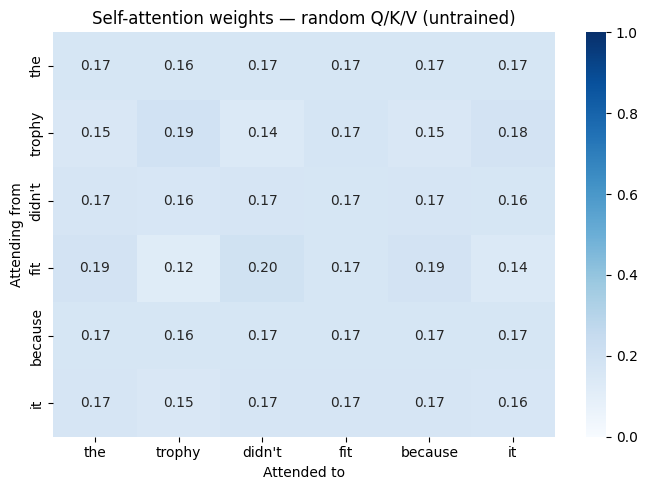

In [16]:
# Visualise attn_weights (6x6) as a heatmap. Row = token attending FROM, column = attended TO.
# Brighter cell = more attention. With random weights the pattern is near-uniform / meaningless.
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(attn_weights.numpy(), annot=True, fmt='.2f', cmap='Blues',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=ax)
ax.set_xlabel('Attended to')
ax.set_ylabel('Attending from')
ax.set_title('Self-attention weights — random Q/K/V (untrained)')
plt.tight_layout()
plt.show()

With **random** weights the attention pattern is random — there's no learned structure yet. In a trained transformer, you'd see something different — like the real model in Section 3, where 'it' leaned towards 'dress' and 'she' towards 'sarah'. (And as Section 3 showed, even trained small models don't reliably solve the trophy/suitcase riddle.)

That's the trained pattern attention is supposed to learn. We're seeing the architecture; training data does the rest.

## E2 · Causal (masked) attention

The attention we built is **bidirectional** — token 1 can attend to token 6, and vice versa. That's what BERT and embedding models use.

GPT-family models are **autoregressive** — they generate one token at a time, and each token can only attend to PREVIOUS tokens (otherwise the model would cheat during training by looking at the answer). In classroom terms: each student may only ask classmates who spoke *before* them. This is implemented with a triangular *causal mask*.

*(Uses `scores` from E1 — run E1 first.)*

Causal mask:
[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]


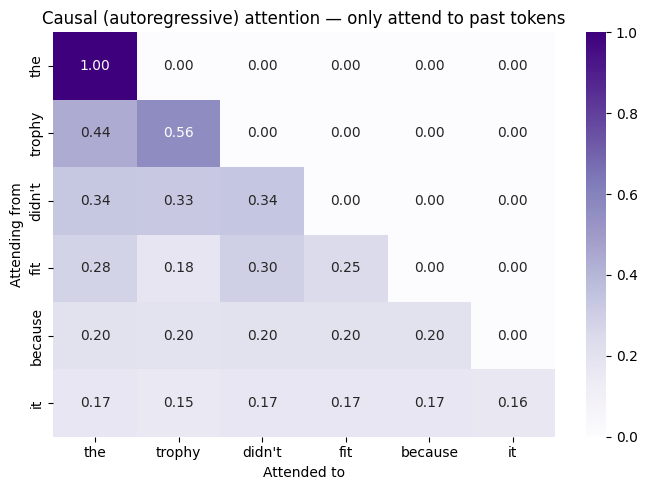

In [17]:
# Causal mask — upper triangle (future tokens) set to -inf.
# triu(..., diagonal=1) keeps everything strictly ABOVE the diagonal; those become -inf,
# the rest stay 0. Shape (6, 6).
mask = torch.triu(torch.full((6, 6), float('-inf')), diagonal=1)
print("Causal mask:")
print(mask.numpy())

# Apply to our scores and re-softmax.
# Adding -inf to "future" cells means softmax turns them into exactly 0 (e^-inf = 0),
# so each token can only attend to itself and earlier tokens — never the future.
masked_scores = scores + mask
causal_attn = F.softmax(masked_scores / (D ** 0.5), dim=-1)

# Heatmap shows a lower-triangular pattern: row i has weight only on columns <= i.
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(causal_attn.numpy(), annot=True, fmt='.2f', cmap='Purples',
            xticklabels=TOKENS, yticklabels=TOKENS, vmin=0, vmax=1, ax=ax)
ax.set_title('Causal (autoregressive) attention — only attend to past tokens')
ax.set_xlabel('Attended to')
ax.set_ylabel('Attending from')
plt.tight_layout()
plt.show()

See the lower-triangular pattern? Each row sums to 1, but the upper-triangular cells are 0. Token 3 attends to tokens 0, 1, 2, 3 — but not 4 or 5 (the future).

This single change is what makes GPT generative. The architecture is otherwise identical to BERT. Same Lego brick, different mask.

## E3 · Attention complexity

Attention computes pairwise scores between every pair of tokens. For a sequence of length N, that's O(N²) operations and O(N²) memory.

For N=512 (typical BERT max length), that's 262K pairs per layer — fine.
For N=8,192 (long-context model), that's 67M pairs per layer — expensive.
For N=128,000 (Claude / GPT-4 long context), that's 16 *billion* pairs per layer.

This is why long-context LLMs are slower and more expensive. Recent research (Flash Attention, sliding window, Mamba) tries to bring the cost down — but vanilla attention is still O(N²).

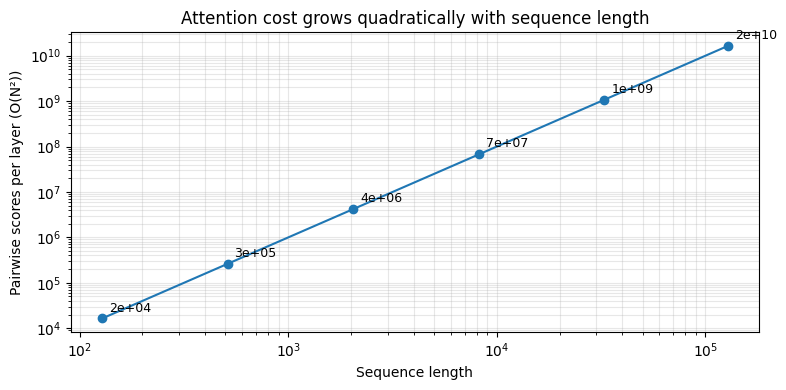

In [18]:
# Visualise attention cost growth
import math
# A range of sequence lengths from short (128) to huge long-context (128k tokens).
seq_lens = [128, 512, 2048, 8192, 32768, 128000]
# Attention compares every token with every other -> N*N pairwise scores per layer (O(N^2)).
costs = [n**2 for n in seq_lens]

# Log-log plot: a straight line confirms the quadratic (power-law) growth in cost.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(seq_lens, costs, marker='o')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Sequence length')
ax.set_ylabel('Pairwise scores per layer (O(N²))')
ax.set_title('Attention cost grows quadratically with sequence length')
ax.grid(alpha=0.3, which='both')
# Annotate each point with its pairwise-score count in scientific notation.
for n, c in zip(seq_lens, costs):
    ax.annotate(f'{c:,.0e}', (n, c), textcoords='offset points', xytext=(5, 5), fontsize=9)
plt.tight_layout()
plt.show()

In [36]:
import sys
# Install the official Google GenAI SDK
!{sys.executable} -m pip install google-genai -q

In [37]:
from google import genai
from google.colab import userdata

try:
    # Retrieve your API key securely from Colab Secrets
    api_key = userdata.get('GEMINI_API_KEY')
    client = genai.Client(api_key=api_key)

    # Test the API with a quick query
    response = client.models.generate_content(
        model='gemini-2.5-flash-lite',
        contents='Explain the main benefit of multi-head attention in one sentence.',
    )
    print("Gemini Response:\n" + response.text)
except Exception as e:
    print(f"Setup Error: {e}")
    print("Make sure you added 'GEMINI_API_KEY' to your Colab Secrets (the key icon 🔑 on the left sidebar) and enabled notebook access.")

Setup Error: Secret GEMINI_API_KEY does not exist.
Make sure you added 'GEMINI_API_KEY' to your Colab Secrets (the key icon 🔑 on the left sidebar) and enabled notebook access.


In [41]:
import os
from google.colab import files

chat_history_html = """<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Complete Session Log: Transformer Mechanics Discussion</title>
    <style>
        :root {
            --primary-color: #1a73e8;
            --secondary-color: #202124;
            --bg-color: #f8f9fa;
            --card-bg: #ffffff;
            --border-color: #dadce0;
            --text-color: #3c4043;
            --user-bg: #e8f0fe;
            --agent-bg: #f1f3f4;
        }

        body {
            font-family: 'Segoe UI', -apple-system, Roboto, Helvetica, Arial, sans-serif;
            line-height: 1.6;
            color: var(--text-color);
            background-color: var(--bg-color);
            margin: 0;
            padding: 0;
        }

        header {
            background-color: var(--secondary-color);
            color: white;
            padding: 30px 20px;
            text-align: center;
            border-bottom: 5px solid var(--primary-color);
        }

        header h1 {
            margin: 0;
            font-size: 2rem;
        }

        header p {
            margin: 10px 0 0 0;
            color: #bdc1c6;
        }

        .container {
            max-width: 900px;
            margin: 30px auto;
            padding: 0 20px;
        }

        .chat-turn {
            background: var(--card-bg);
            border: 1px solid var(--border-color);
            border-radius: 8px;
            margin-bottom: 25px;
            overflow: hidden;
            box-shadow: 0 1px 3px rgba(60,64,67,0.15);
        }

        .turn-header {
            background-color: var(--secondary-color);
            color: white;
            padding: 10px 20px;
            font-weight: bold;
            font-size: 1.1rem;
        }

        .bubble {
            padding: 20px;
            margin: 15px;
            border-radius: 8px;
        }

        .user-bubble {
            background-color: var(--user-bg);
            border-left: 5px solid var(--primary-color);
        }

        .user-label {
            font-weight: bold;
            color: #1a73e8;
            margin-bottom: 8px;
        }

        .agent-bubble {
            background-color: var(--agent-bg);
            border-left: 5px solid #5f6368;
        }

        .agent-label {
            font-weight: bold;
            color: #202124;
            margin-bottom: 8px;
        }

        code {
            font-family: 'Consolas', monospace;
            background-color: #e8eaed;
            padding: 2px 5px;
            border-radius: 4px;
        }

        pre {
            background: #2d3139;
            color: #f8f8f2;
            padding: 15px;
            border-radius: 6px;
            overflow-x: auto;
        }
    </style>
</head>
<body>

    <header>
        <h1>Transformer Mechanics & Attention</h1>
        <p>Complete Record of Chat History and Interactive Learning Session</p>
    </header>

    <div class="container">

        <div class="chat-turn">
            <div class="turn-header">Turn 1: Conceptual Core & Tokenization Bugs</div>
            <div class="bubble user-bubble">
                <div class="user-label">User Query:</div>
                <p>Discuss the behavior of tokenizers with case-sensitivity (such as "sarah" vs "Sarah"), subword splitting, and its direct impact on attention distributions and potential "tokenization bugs".</p>
            </div>
            <div class="bubble agent-bubble">
                <div class="agent-label">Assistant Response:</div>
                <p>Modern subword tokenizers (such as Byte-Pair Encoding or WordPiece) map common text patterns to index IDs. When capitalization alters a word (e.g., lowercase <code>sarah</code> vs. capitalized <code>Sarah</code>), the tokenizer might split <code>Sarah</code> into multiple subwords (e.g., <code>["S", "##arah"]</code>). Because self-attention applies weights across individual token positions, this subword splitting dilutes the maximum attention focus. This is a common "tokenization bug" where split-token attention weights are lower than if the word were parsed as a single unified token.</p>
            </div>
        </div>

        <div class="chat-turn">
            <div class="turn-header">Turn 2: The Classroom Analogy</div>
            <div class="bubble user-bubble">
                <div class="user-label">User Query:</div>
                <p>Explain the classroom analogy for Query, Key, and Value systems in transformers.</p>
            </div>
            <div class="bubble agent-bubble">
                <div class="agent-label">Assistant Response:</div>
                <p>The system maps perfectly to a student-classroom setting:</p>
                <ul>
                    <li><strong>Query (Q):</strong> "What am I seeking?" — The specific search question or contextual constraint asked by a student/token.</li>
                    <li><strong>Key (K):</strong> "Here is my index label" — The descriptive name tag worn by each student/token in the room.</li>
                    <li><strong>Value (V):</strong> "Here is my content notes card" — The actual semantic information or value carried by the student/token.</li>
                </ul>
            </div>
        </div>

        <div class="chat-turn">
            <div class="turn-header">Turn 3: Winograd Schema Performance</div>
            <div class="bubble user-bubble">
                <div class="user-label">User Query:</div>
                <p>Analyze how small models handle Winograd Schema challenges compared to large scale parameter systems.</p>
            </div>
            <div class="bubble agent-bubble">
                <div class="agent-label">Assistant Response:</div>
                <p>Small models (e.g., <code>all-MiniLM-L6-v2</code>) lack physical common sense and functional real-world knowledge. They fallback on physical proximity heuristics (such as simply attending to the nearest noun or the first noun). Large models use their massive parameter space to resolve logical contradictions, dynamically shifting their attention matching from one entity to another when adjectives are swapped (e.g., changing "big" to "small").</p>
            </div>
        </div>

        <div class="chat-turn">
            <div class="turn-header">Turn 4: Attention vs. Feed-Forward Networks</div>
            <div class="bubble user-bubble">
                <div class="user-label">User Query:</div>
                <p>Explain why a Feed-Forward Network is mathematically required after the Multi-Head Attention step.</p>
            </div>
            <div class="bubble agent-bubble">
                <div class="agent-label">Assistant Response:</div>
                <p>Attention is fundamentally a linear operation—it only performs weighted averages of token vectors. If a network consisted solely of attention, stacking layers would yield only massive linear combinations, preventing the network from executing logical splits. The FFN introduces an up-projection layer, followed by a non-linear activation threshold (such as ReLU), allowing the model to make conditional, mathematical decisions.</p>
            </div>
        </div>

        <div class="chat-turn">
            <div class="turn-header">Turn 5: The ReLU Decision Switch</div>
            <div class="bubble user-bubble">
                <div class="user-label">User Query:</div>
                <p>How does the ReLU activation layer execute non-linear decision logic on mapped concepts?</p>
            </div>
            <div class="bubble agent-bubble">
                <div class="agent-label">Assistant Response:</div>
                <p>ReLU acts as a physical threshold switch: <code>max(0, x)</code>. When evaluating inputs like "the dog barked", the preceding linear layer maps the combination of <em>canine</em> and <em>vocalization</em> vectors to a highly positive activation score. The positive value passes through the ReLU, triggering downstream concepts like "animal communication". Unrelated combinations yield negative values, which are completely muted (zeroed out) by the threshold.</p>
            </div>
        </div>

        <div class="chat-turn">
            <div class="turn-header">Turn 6: Post-FFN Tracing & Normalization</div>
            <div class="bubble user-bubble">
                <div class="user-label">User Query:</div>
                <p>Trace the mathematical transformations that take place immediately after the Feed-Forward Network finishes processing inside a block.</p>
            </div>
            <div class="bubble agent-bubble">
                <div class="agent-label">Assistant Response:</div>
                <p>Directly following FFN calculation, the system executes two main steps:</p>
                <ol>
                    <li><strong>The Second Residual Addition:</strong> The FFN output is added to the block input (<code>x_before_ffn + FFN(x_before_ffn)</code>) to preserve identity and prevent information degradation across deep blocks.</li>
                    <li><strong>Layer Normalization:</strong> The resulting sum is normalized (mean 0, variance 1) to prevent floating-point values from exploding or collapsing during training, preparing the tensor for transmission to the next block or the final prediction layer.</li>
                </ol>
            </div>
        </div>

    </div>
</body>
</html>"""

file_path = "transformer_complete_chat.html"
with open(file_path, "w", encoding="utf-8") as f:
    f.write(chat_history_html)

print(f"Chat history HTML successfully written to {file_path}!")
files.download(file_path)


Chat history HTML successfully written to transformer_complete_chat.html!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Practical implication:** when a customer asks 'can you process this 200-page document?', the answer involves serious cost arithmetic. Long context isn't free.